# Tarea 3: SVC gaussiano, árbol de decisión y random forest

**Dataset:** White Wine Quality (UCI). Contiene 4898 vinos blancos, 11 mediciones fisicoquímicas y una evaluación de calidad. Para cumplir la restricción de 5--10 features se modelan 10 variables, dejando `density` fuera. La etiqueta ordinal se agrupa en tres clases: baja (quality <= 5), media (quality == 6) y alta (quality >= 7).

Todas las particiones y búsquedas usan `random_state=42` y la prueba se reserva hasta la evaluación final.

## 1. Kernel cuadrático

Para $K(x,z)=(x^Tz+c)^2$, con $x=(x_1,x_2)$, la transformación es
$$\phi(x)=(x_1^2,\;x_2^2,\;\sqrt{2}x_1x_2,\;\sqrt{2c}x_1,\;\sqrt{2c}x_2,\;c).$$
Así, el producto interno en el espacio transformado reproduce el kernel.

In [1]:
import numpy as np

c = 9
x = np.array([2.0, -3.0])
z = np.array([1.0, 4.0])

def phi(v, c=9):
    return np.array([v[0]**2, v[1]**2, np.sqrt(2)*v[0]*v[1],
                     np.sqrt(2*c)*v[0], np.sqrt(2*c)*v[1], c])

phi_x = phi(x, c)
phi_z = phi(z, c)
kernel_directo = (x @ z + c)**2
producto_phi = phi_x @ phi_z
print('phi([2, -3]) =', phi_x)
print('phi(x)^T phi(z) =', producto_phi)
print('K(x,z) =', kernel_directo)
print('¿Coinciden?', np.isclose(producto_phi, kernel_directo))

phi([2, -3]) = [  4.           9.          -8.48528137   8.48528137 -12.72792206
   9.        ]
phi(x)^T phi(z) = 1.0
K(x,z) = 1.0
¿Coinciden? True


Para $d$ features, un kernel polinómico de grado 2 explícito tiene $d$ términos lineales, $d$ términos cuadrados, $d(d-1)/2$ productos cruzados y un término constante. Por tanto, el número de componentes es

$$
d + d(d-1)/2 + d + 1 = d(d+3)/2 + 1.
$$ 
Calcular directamente $\\phi(x)^T\\phi(z)$ cuesta del orden de $O(d^2)$ porque hay $d(d+3)/2+1$ componentes, mientras que evaluar $(x^Tz+c)^2$ cuesta $O(d)$. Por ejemplo, para $d=100$, $\\phi$ tiene $5151$ componentes: el producto explícito requiere del orden de $5151$ productos, mientras el kernel requiere del orden de $100$. Esta es la ventaja del truco del kernel: no se construye el espacio de mayor dimensión.

## 2. Carga, descripción y limpieza del dataset

Las features usadas son acidez fija, acidez volátil, ácido cítrico, azúcar residual, cloruros, dióxido de azufre libre, dióxido de azufre total, pH, sulfatos y alcohol. Miden, respectivamente, acidez no volátil, acidez volátil, contenido de citratos, azúcar restante, sales, SO2 libre, SO2 total, acidez, compuestos sulfatados y porcentaje de alcohol.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = Path('winequality-white.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('Tarea3/src/winequality-white.csv')
df = pd.read_csv(DATA_PATH, sep=';')
features = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'pH',
            'sulphates', 'alcohol']
df['class'] = pd.cut(df['quality'], bins=[-np.inf, 5, 6, np.inf],
                     labels=['baja', 'media', 'alta'])
print(f'Observaciones: {len(df):,}; features modeladas: {len(features)}')
display(df.head())
display(df[features].describe().T.round(3))
print('Valores faltantes:', int(df[features + ['class']].isna().sum().sum()))
print('Calidad original:')
display(df['quality'].value_counts().sort_index())
print('Proporción por clase:')
display(df['class'].value_counts(normalize=True).sort_index().rename('proportion').round(4))

Observaciones: 4,898; features modeladas: 10


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,class
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,media
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,media
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,media
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,media
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,media


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.855,0.844,3.800,6.300,6.800,7.30,14.200
volatile acidity,4898.0,0.278,0.101,0.080,0.210,0.260,0.32,1.100
citric acid,4898.0,0.334,0.121,0.000,0.270,0.320,0.39,1.660
residual sugar,4898.0,6.391,5.072,0.600,1.700,5.200,9.90,65.800
chlorides,4898.0,0.046,0.022,0.009,0.036,0.043,0.05,0.346
free sulfur dioxide,4898.0,35.308,17.007,2.000,23.000,34.000,46.00,289.000
total sulfur dioxide,4898.0,138.361,42.498,9.000,108.000,134.000,167.00,440.000
pH,4898.0,3.188,0.151,2.720,3.090,3.180,3.28,3.820
sulphates,4898.0,0.490,0.114,0.220,0.410,0.470,0.55,1.080
alcohol,4898.0,10.514,1.231,8.000,9.500,10.400,11.40,14.200


Valores faltantes: 0
Calidad original:


quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64

Proporción por clase:


class
baja     0.3348
media    0.4488
alta     0.2164
Name: proportion, dtype: float64

Filas después de limpieza: 3961


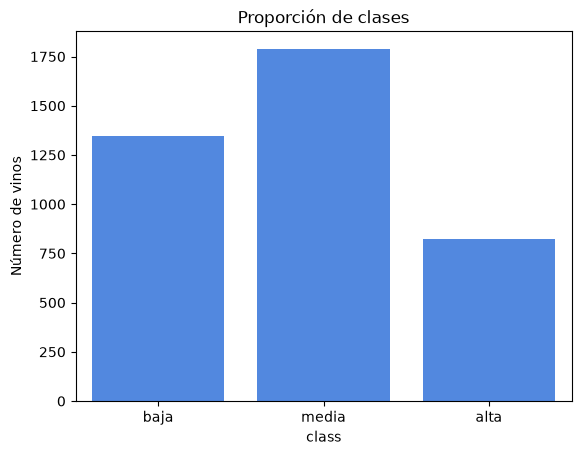

In [3]:
# Se eliminan filas incompletas y duplicados exactos antes del split.
# Los duplicados son registros idénticos: quitarlos no usa estadísticas del conjunto de prueba.
df = df.dropna(subset=features + ['class']).drop_duplicates().reset_index(drop=True)
print('Filas después de limpieza:', len(df))
sns.countplot(data=df, x='class', order=['baja', 'media', 'alta'], color='#3b82f6')
plt.title('Proporción de clases')
plt.ylabel('Número de vinos')
plt.show()

La eliminación de duplicados exactos se hace antes del split porque son registros idénticos y no aportan información nueva; no constituye fuga porque no se usan estadísticas del conjunto de prueba para ajustar el modelo. El `describe()` y las proporciones anteriores son EDA descriptivo del dataset completo; ningún promedio, desviación o distribución del test entra en el ajuste de los modelos.

La clase media es la mayoritaria y las clases baja y alta son menores. La separación estratificada conserva estas proporciones. La exactitud será útil como métrica global, pero también se reportarán precisión y recall por clase para no ocultar el rendimiento de las clases menos frecuentes.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df[features]
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print('Proporciones train:', y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print('Proporciones test:', y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

(3168, 10) (793, 10)
Proporciones train: {'baja': 0.34, 'media': 0.451, 'alta': 0.208}
Proporciones test: {'baja': 0.34, 'media': 0.451, 'alta': 0.208}


## 2.1 SVC con dos features y kernel RBF

Para visualizar fronteras escogemos `alcohol` y `volatile acidity`. El escalado se ajusta solo con train. En el RBF, $K(x,z)=\\exp(-\\gamma\\|x-z\\|^2)$ y $\\gamma=1/(2\\sigma^2)$: gamma grande equivale a sigma pequeño, influencia local y fronteras más onduladas; gamma pequeño produce fronteras más suaves. $C$ penaliza los errores mediante las holguras $\\xi_i$ de la SVM de margen suave: un $C$ grande penaliza más cada holgura, suele estrechar el margen y puede sobreajustar; un $C$ pequeño tolera más errores a cambio de un margen más amplio.

RBF: C=1, gamma=0.01: soporte=2340, acc train=0.548, acc validación=0.546


c:\Users\VICTUS\Documents\VSC\IA\Tarea1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


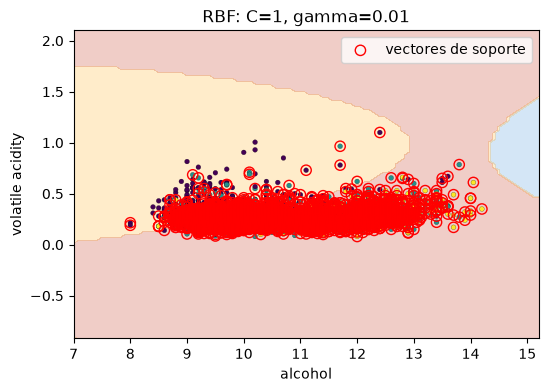

RBF: C=1, gamma=0.1: soporte=2205, acc train=0.569, acc validación=0.571


c:\Users\VICTUS\Documents\VSC\IA\Tarea1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


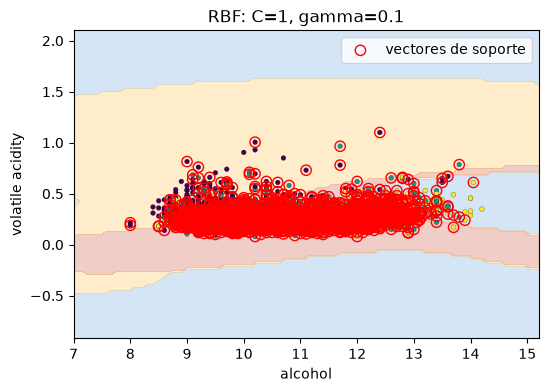

RBF: C=1, gamma=1.0: soporte=2170, acc train=0.582, acc validación=0.601


c:\Users\VICTUS\Documents\VSC\IA\Tarea1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


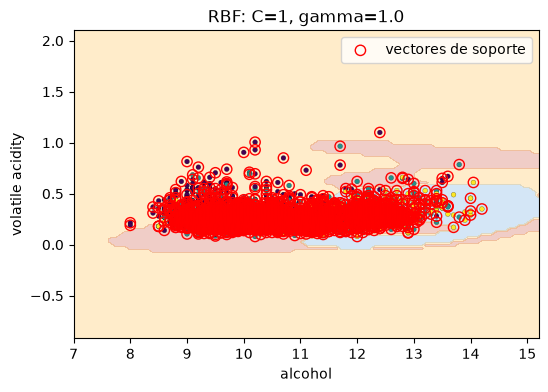

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

visual_features = ['alcohol', 'volatile acidity']
X2_fit, X2_val, y2_fit, y2_val = train_test_split(
    X_train[visual_features], y_train, test_size=0.20,
    stratify=y_train, random_state=RANDOM_STATE)

def fit_report_plot(model, title):
    model.fit(X2_fit, y2_fit)
    train_pred = model.predict(X2_fit)
    val_pred = model.predict(X2_val)
    print(f'{title}: soporte={model[-1].n_support_.sum()}, '
          f'acc train={accuracy_score(y2_fit, train_pred):.3f}, '
          f'acc validación={accuracy_score(y2_val, val_pred):.3f}')
    fig, ax = plt.subplots(figsize=(6, 4))
    DecisionBoundaryDisplay.from_estimator(model, X2_fit, response_method='predict',
        alpha=0.22, cmap='viridis', ax=ax, xlabel=visual_features[0], ylabel=visual_features[1])
    ax.scatter(X2_fit.iloc[:, 0], X2_fit.iloc[:, 1], c=y2_fit.astype('category').cat.codes,
               cmap='viridis', s=12, edgecolor='k', linewidth=0.15)
    support = model[-1].support_
    ax.scatter(X2_fit.iloc[support, 0], X2_fit.iloc[support, 1],
               facecolors='none', edgecolors='red', s=55, linewidth=1.0, label='vectores de soporte')
    ax.set_title(title); ax.legend(); plt.show()
    return model

gamma_values = [0.01, 0.1, 1.0]
gamma_models = []
for gamma in gamma_values:
    gamma_models.append(fit_report_plot(
        Pipeline([('scale', StandardScaler()), ('svc', SVC(kernel='rbf', C=1, gamma=gamma))]),
        f'RBF: C=1, gamma={gamma}'))

RBF: C=0.1, gamma=0.1: soporte=2313, acc train=0.563, acc validación=0.558


c:\Users\VICTUS\Documents\VSC\IA\Tarea1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


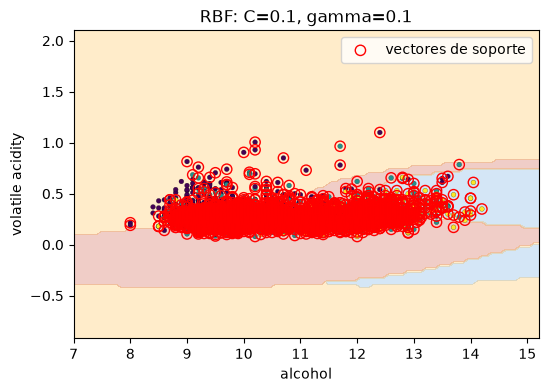

RBF: C=1, gamma=0.1: soporte=2205, acc train=0.569, acc validación=0.571


c:\Users\VICTUS\Documents\VSC\IA\Tarea1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


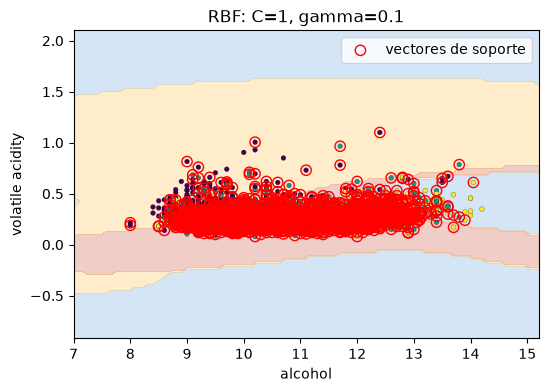

RBF: C=10, gamma=0.1: soporte=2160, acc train=0.567, acc validación=0.576


c:\Users\VICTUS\Documents\VSC\IA\Tarea1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


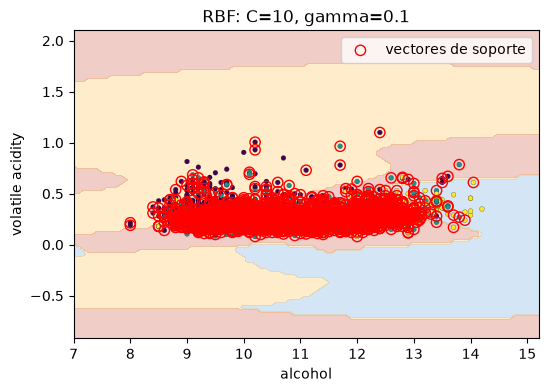

In [6]:
C_values = [0.1, 1, 10]
C_models = []
for C in C_values:
    C_models.append(fit_report_plot(
        Pipeline([('scale', StandardScaler()), ('svc', SVC(kernel='rbf', C=C, gamma=0.1))]),
        f'RBF: C={C}, gamma=0.1'))

### Interpretación de las fronteras RBF

Con $C=1$, al aumentar $\\gamma$ de $0.01$ a $0.1$ y $1.0$, la frontera pasa de ser más suave y global a ser más local y flexible. Esto se observa en los resultados: el número de vectores de soporte baja de $2340$ a $2205$ y $2170$, mientras la exactitud de train sube de $0.548$ a $0.569$ y $0.582$; la exactitud de validación también sube de $0.546$ a $0.571$ y $0.601$. En esta grilla, aumentar gamma mejora la separación en validación, por lo que $\\gamma=0.01$ parece subajustar; no obstante, valores excesivos podrían producir una frontera demasiado ondulada y sobreajuste.

Con $\\gamma=0.1$, al aumentar $C$ de $0.1$ a $1$ y $10$, la penalización de las holguras $\\xi_i$ aumenta: el modelo tolera menos errores de entrenamiento, el margen tiende a hacerse más estrecho y la frontera puede adaptarse más a los datos. Los vectores de soporte bajan de $2313$ a $2205$ y $2160$, mientras la exactitud de train es $0.563$, $0.569$ y $0.567$; la exactitud de validación es $0.558$, $0.571$ y $0.576$. En estos valores, $C=0.1$ es el más restrictivo respecto al margen y muestra el menor desempeño de validación; aumentar $C$ hasta $10$ mejora ligeramente la validación. Si al seguir aumentando $C$ la exactitud de train continuara separándose de validación, sería evidencia de sobreajuste; aquí la diferencia aún es pequeña.

## 2.2 Selección de C y gamma con GridSearchCV

El `Pipeline` evita que el escalado use información de validación: en cada partición de la validación cruzada, `StandardScaler` se ajusta solo con la parte de entrenamiento. La grilla siguiente contiene $5\times5=25$ combinaciones y, con 5 folds, ajusta 125 modelos (más el refit final). `best_score_` es el promedio de validación cruzada del mejor candidato, no el score del conjunto de prueba.

Mejores hiperparámetros: {'svc__C': np.float64(1.0), 'svc__gamma': np.float64(0.1)}
best_score_ (f1_macro CV): 0.5812
Modelos de la grilla: 25


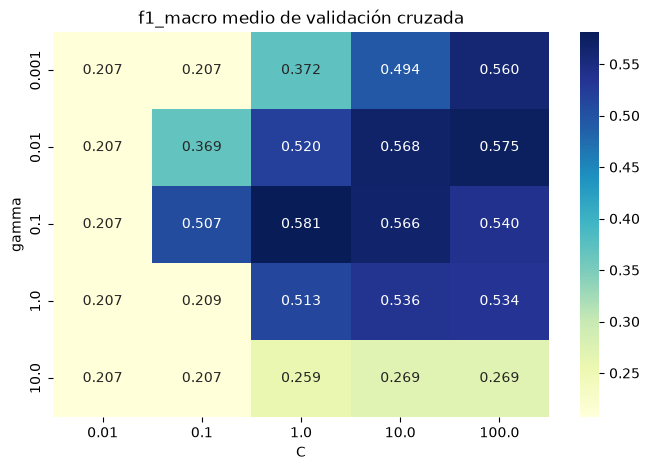

In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
svc_pipe = Pipeline([('scale', StandardScaler()), ('svc', SVC(kernel='rbf'))])
svc_grid = {'svc__C': np.logspace(-2, 2, 5), 'svc__gamma': np.logspace(-3, 1, 5)}
svc_search = GridSearchCV(svc_pipe, svc_grid, cv=cv, scoring='f1_macro', n_jobs=-1, return_train_score=True)
svc_search.fit(X_train, y_train)
print('Mejores hiperparámetros:', svc_search.best_params_)
print(f'best_score_ (f1_macro CV): {svc_search.best_score_:.4f}')
print('Modelos de la grilla:', len(svc_search.cv_results_['params']))
cv_table = pd.DataFrame(svc_search.cv_results_)
heat = cv_table.pivot(index='param_svc__gamma', columns='param_svc__C', values='mean_test_score')
plt.figure(figsize=(8, 5))
sns.heatmap(heat.astype(float), annot=True, fmt='.3f', cmap='YlGnBu')
plt.title('f1_macro medio de validación cruzada')
plt.xlabel('C'); plt.ylabel('gamma'); plt.show()

## 3. Árbol de decisión y random forest

Se usa la misma separación de prueba. El árbol selecciona en cada nodo una pregunta del tipo `feature <= umbral` que reduce la impureza. Un árbol muy profundo puede memorizar el train; por eso se busca `max_depth` con validación cruzada. Random forest combina árboles entrenados con muestras bootstrap y subconjuntos aleatorios de features; promediar sus predicciones reduce la varianza.

Árbol óptimo:  {'max_depth': 4} f1_macro CV= 0.5349


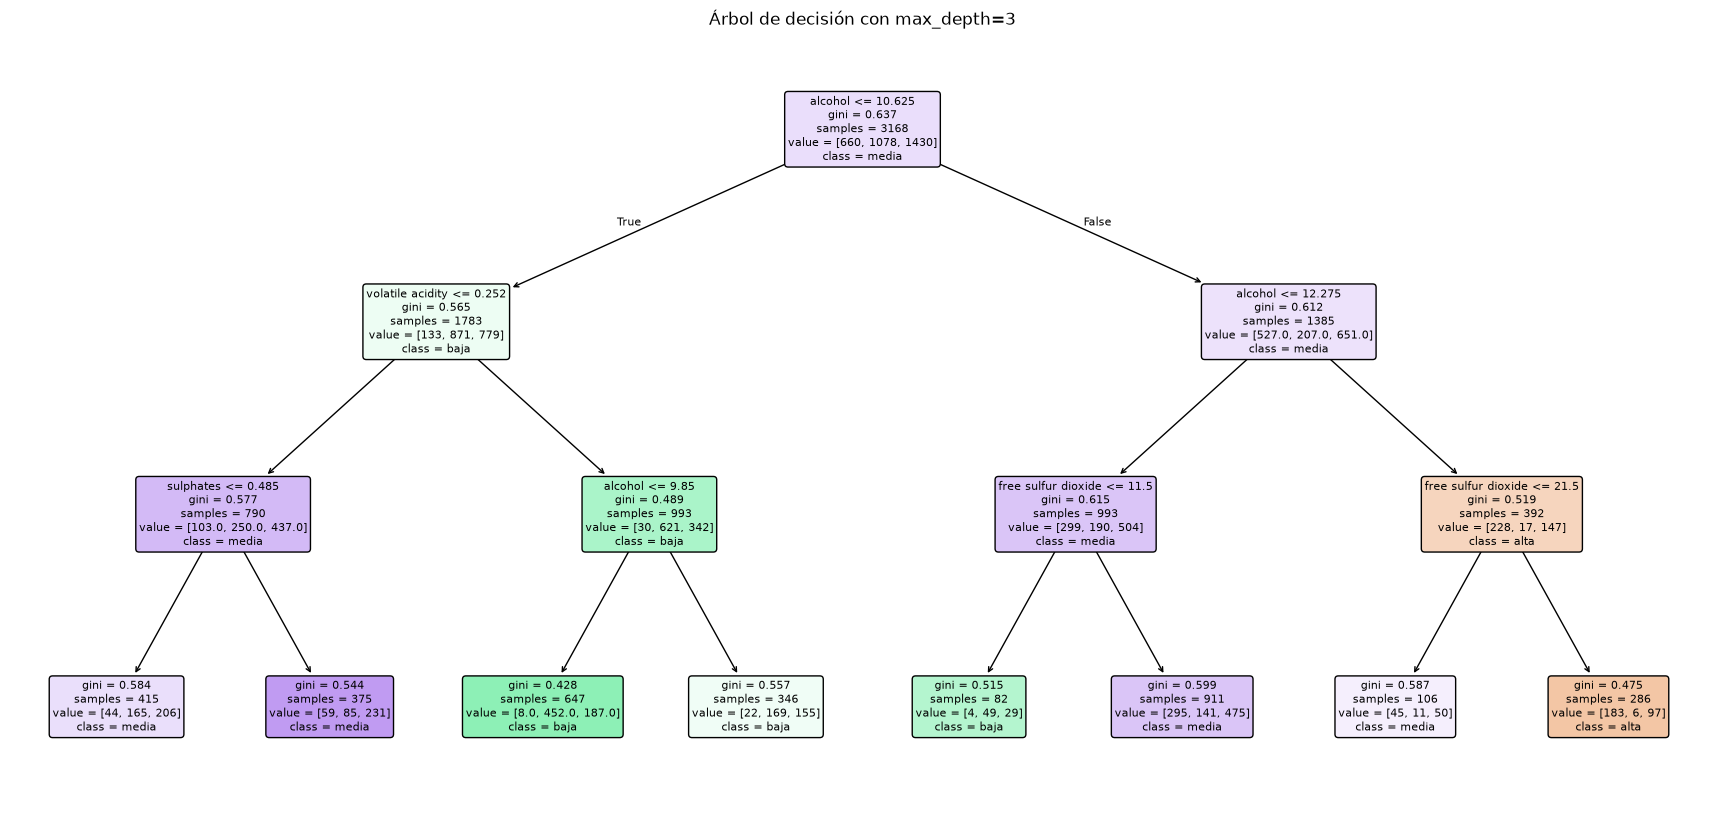

dt3 accuracy train: 0.5729
dt3 accuracy test : 0.5372
Cada nodo pregunta si una feature es menor o igual que un umbral; la hoja devuelve la clase mayoritaria y predict_proba sus proporciones.


In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {'max_depth': [2, 3, 4, 5, 6, 8, 10, None]}, cv=cv, scoring='f1_macro', n_jobs=-1)
tree_search.fit(X_train, y_train)
tree_model = tree_search.best_estimator_
print('Árbol óptimo: ', tree_search.best_params_, 'f1_macro CV=', round(tree_search.best_score_, 4))

# Este es un árbol independiente entrenado realmente con max_depth=3.
dt3 = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
plt.figure(figsize=(22, 10))
plot_tree(dt3, feature_names=features, class_names=dt3.classes_,
          filled=True, rounded=True, fontsize=8)
plt.title('Árbol de decisión con max_depth=3')
plt.show()
print('dt3 accuracy train:', round(dt3.score(X_train, y_train), 4))
print('dt3 accuracy test :', round(dt3.score(X_test, y_test), 4))
print('Cada nodo pregunta si una feature es menor o igual que un umbral; la hoja devuelve la clase mayoritaria y predict_proba sus proporciones.')

### Interpretación del árbol con `max_depth=3`

La raíz pregunta si `alcohol <= 10.625`. Si la respuesta es sí, el árbol pregunta si `volatile acidity <= 0.2525`; en ese subárbol, `sulphates <= 0.485` lleva a hojas que predicen **media**, mientras que `sulphates > 0.485` lleva a `media` en la rama mostrada. Si `volatile acidity > 0.2525`, se pregunta si `alcohol <= 9.85`: ambas hojas de este subárbol predicen **baja**, correspondientes a vinos con menor alcohol y mayor acidez volátil relativa.

Si `alcohol > 10.625`, el árbol pregunta si `alcohol <= 12.275`. Para vinos en ese intervalo, la siguiente división es `free sulfur dioxide <= 11.5`: la hoja izquierda predice **baja** y la derecha **media**. Para `alcohol > 12.275`, se pregunta si `free sulfur dioxide <= 21.5`: valores hasta ese umbral terminan en una hoja **media**, mientras que valores mayores terminan en una hoja **alta**. En consecuencia, las hojas no representan reglas químicas absolutas, sino la clase mayoritaria de los vinos de entrenamiento que comparten cada región: alcohol bajo y acidez volátil relativamente alta tienden a `baja`, mientras que alcohol alto y más dióxido de azufre libre terminan en `alta`; las regiones intermedias se predicen como `media`.

In [9]:
# Ejemplo de recorrido: cada nodo consulta una feature y un umbral hasta llegar a una hoja.
sample = X_test.iloc[[0]]
node_indicator = tree_model.decision_path(sample)
node_ids = node_indicator.indices
print('Ejemplo:', sample.iloc[0].to_dict())
for node_id in node_ids:
    feature_id = tree_model.tree_.feature[node_id]
    if feature_id != -2:
        threshold = tree_model.tree_.threshold[node_id]
        value = sample.iloc[0, feature_id]
        direction = 'izquierda (<=)' if value <= threshold else 'derecha (>)'
        print(f"Nodo {node_id}: {features[feature_id]}={value:.3f}; umbral={threshold:.3f} -> {direction}")
print('predict:', tree_model.predict(sample)[0])
print('predict_proba:', np.round(tree_model.predict_proba(sample)[0], 3), '(orden:', list(tree_model.classes_), ')')

Ejemplo: {'fixed acidity': 5.8, 'volatile acidity': 0.28, 'citric acid': 0.66, 'residual sugar': 9.1, 'chlorides': 0.039, 'free sulfur dioxide': 26.0, 'total sulfur dioxide': 159.0, 'pH': 3.66, 'sulphates': 0.55, 'alcohol': 10.8}
Nodo 0: alcohol=10.800; umbral=10.625 -> derecha (>)
Nodo 16: alcohol=10.800; umbral=12.275 -> izquierda (<=)
Nodo 17: free sulfur dioxide=26.000; umbral=11.500 -> derecha (>)
Nodo 21: pH=3.660; umbral=3.295 -> derecha (>)
predict: alta
predict_proba: [0.467 0.079 0.454] (orden: ['alta', 'baja', 'media'] )


In [10]:
# Recorrido sobre el árbol de profundidad 3 mostrado arriba.
sample = X_test.iloc[[0]]
node_indicator = dt3.decision_path(sample)
node_ids = node_indicator.indices
print('Recorrido de dt3 para el ejemplo:', sample.iloc[0].to_dict())
for node_id in node_ids:
    feature_id = dt3.tree_.feature[node_id]
    if feature_id != -2:
        threshold = dt3.tree_.threshold[node_id]
        value = sample.iloc[0, feature_id]
        direction = 'izquierda (<=)' if value <= threshold else 'derecha (>)'
        print(f"Nodo {node_id}: {features[feature_id]}={value:.3f}; umbral={threshold:.3f} -> {direction}")
print('predict de dt3:', dt3.predict(sample)[0])
print('predict_proba de dt3:', np.round(dt3.predict_proba(sample)[0], 3), '(orden:', list(dt3.classes_), ')')

Recorrido de dt3 para el ejemplo: {'fixed acidity': 5.8, 'volatile acidity': 0.28, 'citric acid': 0.66, 'residual sugar': 9.1, 'chlorides': 0.039, 'free sulfur dioxide': 26.0, 'total sulfur dioxide': 159.0, 'pH': 3.66, 'sulphates': 0.55, 'alcohol': 10.8}
Nodo 0: alcohol=10.800; umbral=10.625 -> derecha (>)
Nodo 8: alcohol=10.800; umbral=12.275 -> izquierda (<=)
Nodo 9: free sulfur dioxide=26.000; umbral=11.500 -> derecha (>)
predict de dt3: media
predict_proba de dt3: [0.324 0.155 0.521] (orden: ['alta', 'baja', 'media'] )


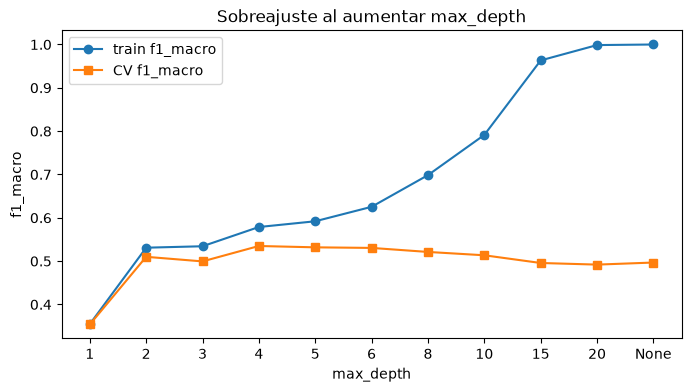

La brecha creciente entre train y CV indica sobreajuste; la elección se hace con CV, no con el score de prueba.


In [12]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None]
train_f1, cv_f1 = [], []
for depth in depths:
    depth_search = GridSearchCV(
        DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE),
        {'max_depth': [depth]}, cv=cv, scoring='f1_macro',
        return_train_score=True, n_jobs=-1)
    depth_search.fit(X_train, y_train)
    train_f1.append(depth_search.cv_results_['mean_train_score'][0])
    cv_f1.append(depth_search.best_score_)

plt.figure(figsize=(8, 4))
labels = [str(depth) for depth in depths]
plt.plot(labels, train_f1, marker='o', label='train f1_macro')
plt.plot(labels, cv_f1, marker='s', label='CV f1_macro')
plt.xlabel('max_depth'); plt.ylabel('f1_macro'); plt.legend()
plt.title('Sobreajuste al aumentar max_depth')
plt.show()
print('La brecha creciente entre train y CV indica sobreajuste; la elección se hace con CV, no con el score de prueba.')

Random forest: {'forest__max_depth': 20, 'forest__max_features': 'sqrt', 'forest__n_estimators': 100} f1_macro CV= 0.5948


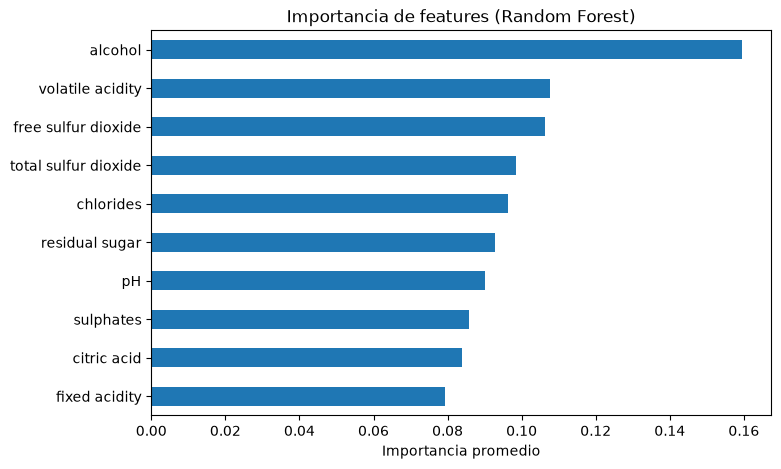

alcohol                 0.159
volatile acidity        0.108
free sulfur dioxide     0.106
total sulfur dioxide    0.098
chlorides               0.096
residual sugar          0.093
pH                      0.090
sulphates               0.086
citric acid             0.084
fixed acidity           0.079
dtype: float64


In [13]:
forest_pipe = Pipeline([('forest', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
forest_grid = {
    'forest__n_estimators': [100, 250],
    'forest__max_depth': [None, 10, 20],
    'forest__max_features': ['sqrt', 0.7]
}
forest_search = GridSearchCV(forest_pipe, forest_grid, cv=cv, scoring='f1_macro', n_jobs=-1)
forest_search.fit(X_train, y_train)
forest_model = forest_search.best_estimator_
print('Random forest:', forest_search.best_params_, 'f1_macro CV=', round(forest_search.best_score_, 4))

importances = pd.Series(
    forest_model.named_steps['forest'].feature_importances_, index=features
).sort_values()
importances.plot.barh(figsize=(8, 5), title='Importancia de features (Random Forest)')
plt.xlabel('Importancia promedio')
plt.show()
print(importances.sort_values(ascending=False).round(3))

## 4. Evaluación final y comparación

El conjunto de prueba se usa aquí una sola vez para cada modelo final. Se muestran accuracy, precisión y sensibilidad (recall) por clase. En una aplicación donde sea más costoso no detectar vinos de calidad alta o baja, `accuracy` no sería suficiente: se podría usar `balanced_accuracy`, `f1_macro` o un scoring ponderado por el costo de cada error. En este dataset la clase media domina, por lo que también se debe observar el recall de baja y alta.


SVC RBF
Accuracy de prueba: 0.5952
              precision    recall  f1-score   support

        baja       0.68      0.60      0.64       270
       media       0.55      0.72      0.63       358
        alta       0.60      0.32      0.41       165

    accuracy                           0.60       793
   macro avg       0.61      0.54      0.56       793
weighted avg       0.60      0.60      0.58       793


Árbol
Accuracy de prueba: 0.5410
              precision    recall  f1-score   support

        baja       0.64      0.47      0.54       270
       media       0.51      0.65      0.57       358
        alta       0.49      0.42      0.45       165

    accuracy                           0.54       793
   macro avg       0.55      0.51      0.52       793
weighted avg       0.55      0.54      0.54       793


Random forest
Accuracy de prueba: 0.5965
              precision    recall  f1-score   support

        baja       0.69      0.59      0.63       270
       media     

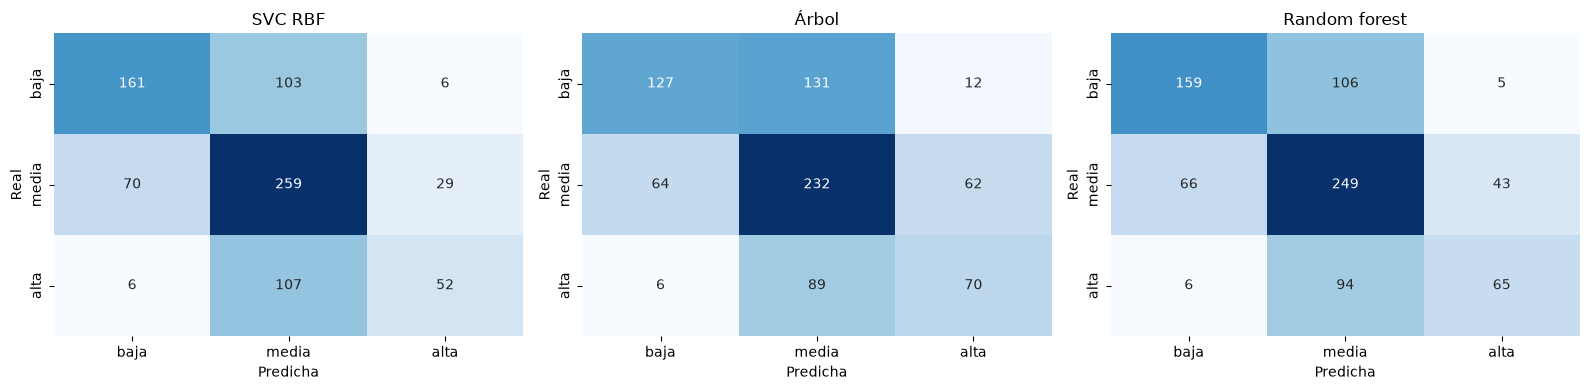

In [14]:
svc_final = svc_search.best_estimator_
models = {'SVC RBF': svc_final, 'Árbol': tree_model, 'Random forest': forest_model}
predictions = {}
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    print(f'\n{name}')
    print('Accuracy de prueba:', f'{accuracy_score(y_test, pred):.4f}')
    print(classification_report(y_test, pred, labels=['baja', 'media', 'alta'], zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=['baja', 'media', 'alta'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['baja', 'media', 'alta'], yticklabels=['baja', 'media', 'alta'])
    ax.set_title(name); ax.set_xlabel('Predicha'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

### Comparación con `class_weight`

`class_weight='balanced'` asigna a cada clase un peso inversamente proporcional a su frecuencia, haciendo que los errores en clases pequeñas influyan más en el ajuste. Se compara SVC y random forest con los mismos hiperparámetros seleccionados sin pesos; esto es una comparación controlada del efecto de los pesos, no una nueva búsqueda de hiperparámetros. Si aumenta el recall de las clases minoritarias a costa de accuracy, aparece el intercambio esperado y la elección depende del costo de cada error.


SVC sin class_weight
Accuracy: 0.5952
              precision    recall  f1-score   support

        baja       0.68      0.60      0.64       270
       media       0.55      0.72      0.63       358
        alta       0.60      0.32      0.41       165

    accuracy                           0.60       793
   macro avg       0.61      0.54      0.56       793
weighted avg       0.60      0.60      0.58       793


SVC balanced
Accuracy: 0.5624
              precision    recall  f1-score   support

        baja       0.65      0.70      0.67       270
       media       0.58      0.42      0.49       358
        alta       0.44      0.66      0.53       165

    accuracy                           0.56       793
   macro avg       0.56      0.59      0.56       793
weighted avg       0.58      0.56      0.56       793



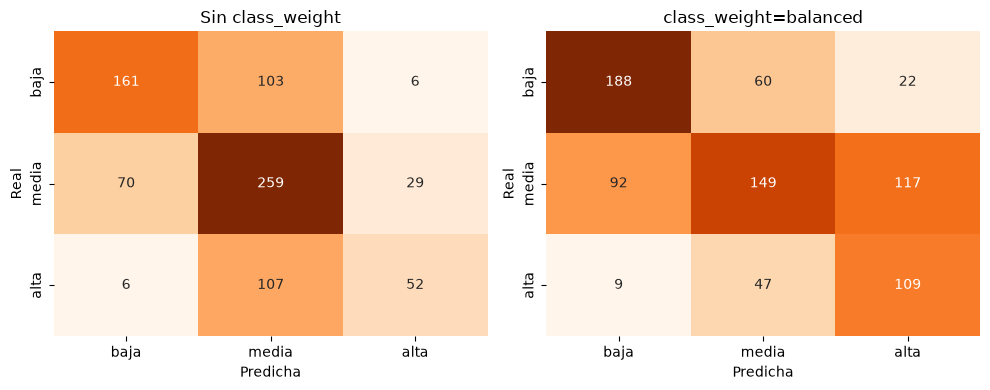

In [15]:
svc_balanced = Pipeline([
    ('scale', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=svc_search.best_params_['svc__C'],
                 gamma=svc_search.best_params_['svc__gamma'], class_weight='balanced'))
])
svc_balanced.fit(X_train, y_train)
balanced_pred = svc_balanced.predict(X_test)
for name, pred in [('sin class_weight', predictions['SVC RBF']), ('balanced', balanced_pred)]:
    print('\nSVC', name)
    print('Accuracy:', round(accuracy_score(y_test, pred), 4))
    print(classification_report(y_test, pred, labels=['baja', 'media', 'alta'], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, pred) in zip(axes, [('Sin class_weight', predictions['SVC RBF']), ('class_weight=balanced', balanced_pred)]):
    cm = confusion_matrix(y_test, pred, labels=['baja', 'media', 'alta'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax,
                xticklabels=['baja', 'media', 'alta'], yticklabels=['baja', 'media', 'alta'])
    ax.set_title(title); ax.set_xlabel('Predicha'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()


Random Forest balanced
Accuracy: 0.5813
              precision    recall  f1-score   support

        baja       0.66      0.61      0.63       270
       media       0.56      0.56      0.56       358
        alta       0.51      0.59      0.55       165

    accuracy                           0.58       793
   macro avg       0.58      0.58      0.58       793
weighted avg       0.59      0.58      0.58       793



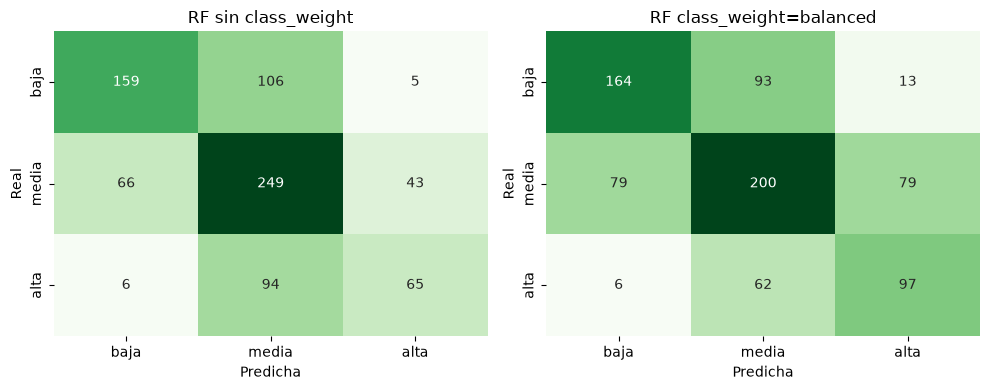

,accuracy,recall baja,recall media,recall alta,f1_macro
modelo,,,,,
SVC,0.595,0.596,0.723,0.315,0.558
SVC balanced,0.562,0.696,0.416,0.661,0.562
RF,0.596,0.589,0.696,0.394,0.573
RF balanced,0.581,0.607,0.559,0.588,0.580


In [16]:
rf_params = {key.replace('forest__', ''): value for key, value in forest_search.best_params_.items()}
rf_balanced = RandomForestClassifier(
    random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced', **rf_params)
rf_balanced.fit(X_train, y_train)
rf_bal_pred = rf_balanced.predict(X_test)
print('\nRandom Forest balanced')
print('Accuracy:', round(accuracy_score(y_test, rf_bal_pred), 4))
print(classification_report(y_test, rf_bal_pred, labels=['baja', 'media', 'alta'], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (title, pred) in zip(axes, [
    ('RF sin class_weight', predictions['Random forest']),
    ('RF class_weight=balanced', rf_bal_pred)]):
    cm = confusion_matrix(y_test, pred, labels=['baja', 'media', 'alta'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=['baja', 'media', 'alta'], yticklabels=['baja', 'media', 'alta'])
    ax.set_title(title); ax.set_xlabel('Predicha'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

from sklearn.metrics import f1_score, recall_score
comparison = []
for name, pred in [
    ('SVC', predictions['SVC RBF']), ('SVC balanced', balanced_pred),
    ('RF', predictions['Random forest']), ('RF balanced', rf_bal_pred)]:
    comparison.append({
        'modelo': name,
        'accuracy': accuracy_score(y_test, pred),
        'recall baja': recall_score(y_test, pred, labels=['baja', 'media', 'alta'], average=None, zero_division=0)[0],
        'recall media': recall_score(y_test, pred, labels=['baja', 'media', 'alta'], average=None, zero_division=0)[1],
        'recall alta': recall_score(y_test, pred, labels=['baja', 'media', 'alta'], average=None, zero_division=0)[2],
        'f1_macro': f1_score(y_test, pred, labels=['baja', 'media', 'alta'], average='macro', zero_division=0)
    })
display(pd.DataFrame(comparison).set_index('modelo').round(3))

## Conclusiones para este problema

- SVC RBF necesita estandarización y modela fronteras no lineales, pero su entrenamiento y ajuste pueden ser costosos y sus decisiones son menos interpretables.
- El árbol es fácil de explicar y visualizar, pero una profundidad grande sobreajusta; `max_depth` controla directamente esa complejidad.
- Random forest suele ser más robusto que un árbol individual y no necesita estandarización, aunque usa más memoria y es menos interpretable que un solo árbol.
- Como la clase media es mayoritaria, optimizar `f1_macro` da el mismo peso a las tres clases y es más coherente que optimizar solo accuracy. En la matriz de confusión se debe revisar especialmente el recall de baja y alta.
- La selección final entre SVC y random forest debe considerar accuracy, `f1_macro`, recall por clase, costo computacional e interpretabilidad. Las cifras observadas pueden cambiar al optimizar `f1_macro`, por lo que se reportan las métricas generadas por esta ejecución y no se afirma un ganador universal.
- `class_weight='balanced'` suele aumentar el peso de las clases minoritarias; la tabla y las matrices anteriores muestran concretamente si mejora sus recalls y qué costo tiene en accuracy o recall de la clase media.